Predict future averge price of all food monthly by using SARIMAX model and Linear Regression Model
* According to the result, we can't know which model is better because of the causes of Covid 19 and Political changes.

### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# for Checking Random Walk
from statsmodels.tsa.stattools import adfuller

In [4]:
# For Prediction
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# LinearRegression
from sklearn.linear_model import LinearRegression

In [5]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [6]:
# For Normalization
from sklearn.preprocessing import MinMaxScaler

In [7]:
# Custom module
from TimeSeriesCustFunc import *

__SARIMAX_Graph__(`data`, `col`, `pred`, `time_range`, `title`, `xlabel, ylabel`, `legend=['Observed', 'Predicted']`)
* __SARIMAX_Graph__(`data`, `col_to_pred`, `[pred, pred_ci]`, `[time_range_for_Observation, time_range_for_Prediction]`, `title_of_plot`, `xlabel`, `ylabel`, `[legend_for_Observation, legend_for_Prediction]`)

__Run_SARIMAX__(`data`, `mod_order`, `time_range`, `col`, `season_order=(0,0,0,0)`, `title=''`, `xlabel=''`, `ylabel=''`)
* __Run_SARIMAX__(`data`, `(p, d, q)`, `[time_range_for_Observation, time_range_for_Prediction]`, `col_to_pred`, `(P, D, Q, m)`, `title_of_plot`, `xlabel`, `ylabel`)
* return model

__AIC_BIC_withOrderRange__(`data`, `p=1`, `d=1`, `q=1`, `P=1`, `D=1`, `Q=1`, `m=1`)
* Compute accuracy with AIC, BIC
* p, d, q, P, D, Q, m must be greater than 0
* return AIC, BIC

__LoadClean_wfp_food_prices_mmr()__
* Load wfp_food_prices_mmr(Cleaned).csv and clean the data
* return DF

### Set Global Variables

In [8]:
obv_st_date = pd.to_datetime("2008-01-01")
obv_end_date = pd.to_datetime("2022-02-01")
pred_st_date = pd.to_datetime("2009-01-01")
pred_end_date = pd.to_datetime("2025-01-01")

### Loading and Cleaning data

In [9]:
data = LoadClean_wfp_food_prices_mmr()
data.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [10]:
data.shape

(31972, 14)

In [11]:
data.isnull().sum()

date                   0
region                 0
city                   0
market                 0
category               0
commodity              0
Exact Commodity        0
Quality            25706
unit                   0
priceflag              0
pricetype              0
currency               0
price                  0
usdprice               0
dtype: int64

### Preparing for Prediction

In [12]:
DAFM = data.copy()
DAFM = DAFM[['date', 'price']]
DAFM['date'] = pd.to_datetime(DAFM['date'])
mask = (DAFM['date']>=obv_st_date) & (DAFM['date']<=obv_end_date)
DAFM = DAFM.loc[mask]
DAFM = DAFM.set_index('date')
DAFM.head()

,price
date,
2008-01-15,400.00
2008-01-15,3636.36
2008-01-15,3636.36
2008-01-15,242.42
2008-01-15,969.70


In [13]:
DAFM = DAFM.resample('MS').mean()
DAFM.head()

,price
date,
2008-01-01,1056.864390
2008-02-01,1136.594375
2008-03-01,1091.044937
2008-04-01,1011.162530
2008-05-01,1011.921319


In [14]:
price = DAFM['price']
date = DAFM.index

##### Normalized the data

In [15]:
scaler = MinMaxScaler()

In [16]:
DAFM_nor = scaler.fit_transform(DAFM)
DAFM_nor = pd.DataFrame(DAFM_nor)
DAFM_nor.head()

,0
0,0.197472
1,0.242857
2,0.216929
3,0.171456
4,0.171888


In [17]:
DAFM_nor['date']=date
DAFM_nor = DAFM_nor.set_index('date')
DAFM_nor.columns=['price']
DAFM_nor.head()

,price
date,
2008-01-01,0.197472
2008-02-01,0.242857
2008-03-01,0.216929
2008-04-01,0.171456
2008-05-01,0.171888


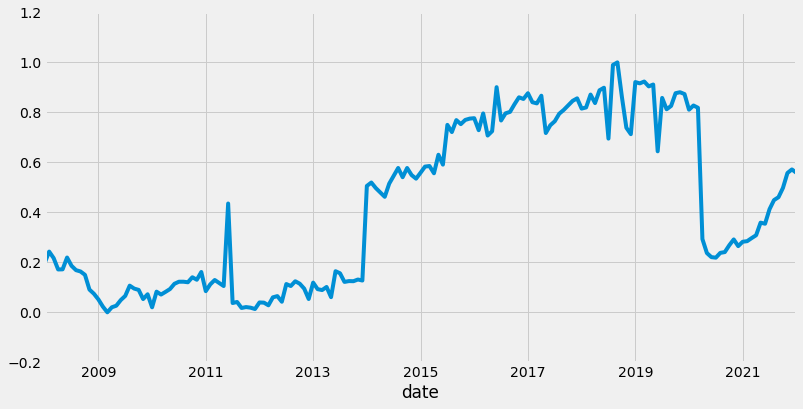

In [18]:
plt.rcParams.update({'figure.figsize': (12,6)})
DAFM_nor['price'].plot()

Nearly Positive Trend

In [19]:
DAFM_nor_diff = DAFM_nor.diff(1).dropna()
DAFM_nor_diff.head()

,price
date,
2008-02-01,0.045385
2008-03-01,-0.025929
2008-04-01,-0.045472
2008-05-01,0.000432
2008-06-01,0.047272


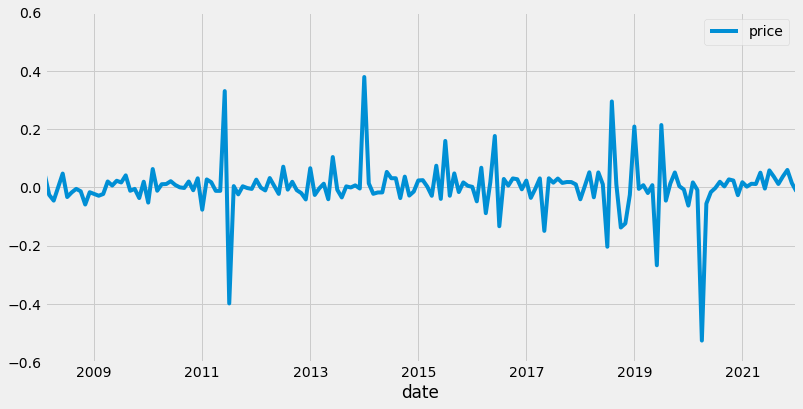

In [20]:
DAFM_nor_diff.plot(grid=True)
plt.show()

##### Checking Random Walk

In [21]:
RW_DAFM = adfuller(DAFM_nor_diff['price'])
RW_DAFM[1] # print P-value. If p-value<5%, reject null hypothesis

3.2537466973232263e-29

##### Plotting ACF and PACF

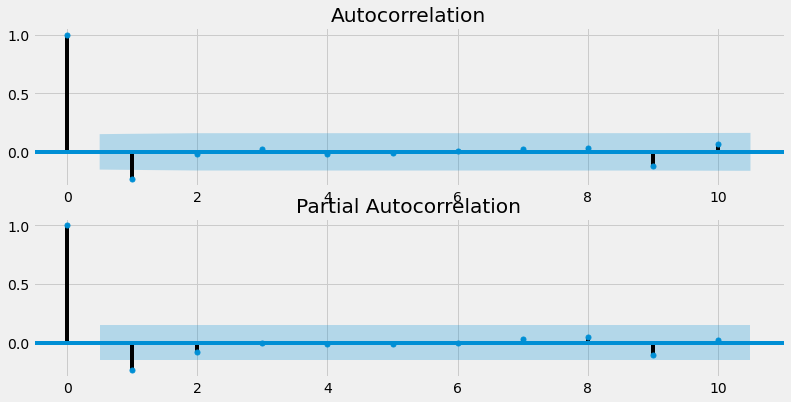

In [22]:
fig, axes=plt.subplots(2,1)
plot_acf(DAFM_nor_diff, lags=10, ax=axes[0])
plot_pacf(DAFM_nor_diff, lags=10, ax=axes[1])
plt.show()

##### Choose smallest AIC and BIC

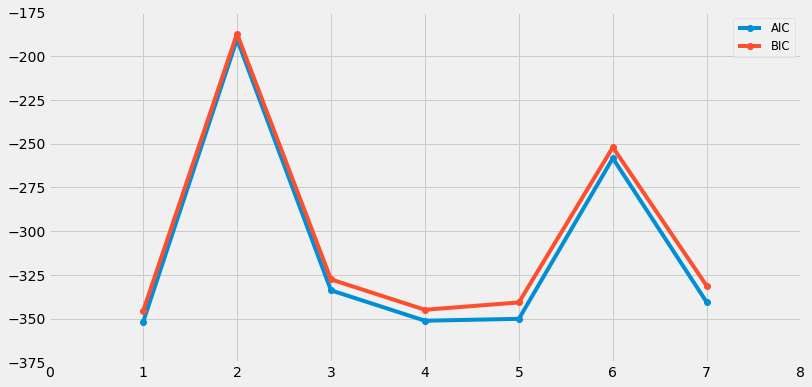

In [23]:
AIC, BIC = AIC_BIC_withOrderRange(DAFM_nor_diff, p=2, d=2, q=2)
# 0:(0,0,0), 1:(0,0,1), 2:(0,1,0), 3:(0,1,1), 4:(1,0,0), 5:(1,0,1), 6:(1,1,0), 7:(1,1,1)

In [24]:
AIC, BIC

(array([-343.92847908, -352.13483278, -190.32149415, -333.85144243,
        -351.22981381, -350.15336262, -258.35942148, -340.74276979]),
 array([-340.8045151 , -345.88690482, -187.20350034, -327.6154548 ,
        -344.98188585, -340.78147068, -252.12343386, -331.38878836]))

##### We will run again  1:(0,0,1), 4:(1,0,0), 5:(1,0,1)

In [25]:
mod_orders = [
    (0,0,1), 
    (1,0,0), 
    (1,0,1)
]

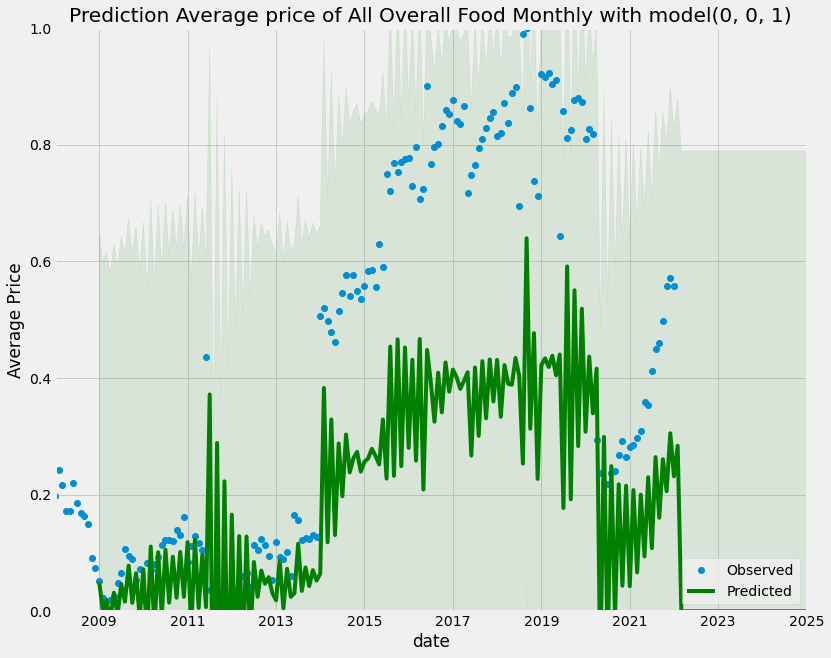

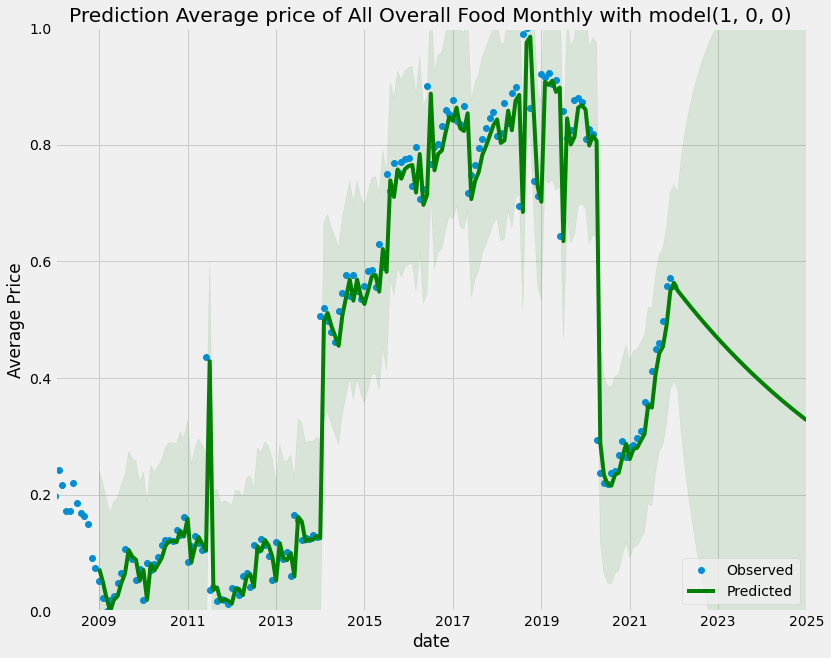

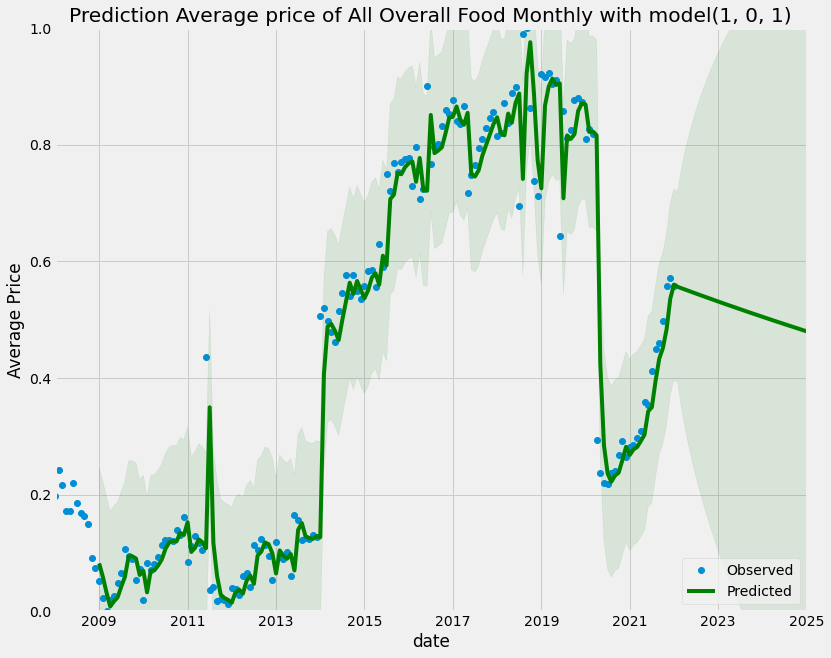

In [26]:
DAFM_models = []
for ind, order in enumerate(mod_orders): 
    model = Run_SARIMAX(DAFM_nor, mod_order=order, time_range=[[obv_st_date, obv_end_date], [pred_st_date, pred_end_date]], col='price', title='Prediction Average price of All Overall Food Monthly with model'+str(order), xlabel='Date', ylabel='Average Price')
    DAFM_models.append(model)

Now we choose (1, 0, 0)

In [27]:
DAFM_model = DAFM_models[2]

In [28]:
DAFM_pred_normalized = DAFM_model.predict(pred_st_date, pred_end_date)
DAFM_pred_normalized

2009-01-01    0.082157
2009-02-01    0.059160
2009-03-01    0.032003
2009-04-01    0.008177
2009-05-01    0.016991
                ...   
2024-09-01    0.488218
2024-10-01    0.486165
2024-11-01    0.484121
2024-12-01    0.482086
2025-01-01    0.480059
Freq: MS, Length: 193, dtype: float64

In [29]:
mask = (DAFM_nor.index>=pred_st_date) & (DAFM_nor.index<=pred_end_date)
DAFM_pred = DAFM_nor.loc[mask]
DAFM_pred

,price
date,
2009-01-01,0.051558
2009-02-01,0.022811
2009-03-01,0.000000
2009-04-01,0.020129
2009-05-01,0.026369
...,...
2021-09-01,0.460496
2021-10-01,0.497753
2021-11-01,0.557326


In [30]:
pred_date = DAFM_pred_normalized.index
pred_date = pred_date[:-1] # the last index doesn't need
pred_date

DatetimeIndex(['2009-01-01', '2009-02-01', '2009-03-01', '2009-04-01',
               '2009-05-01', '2009-06-01', '2009-07-01', '2009-08-01',
               '2009-09-01', '2009-10-01',
               ...
               '2024-03-01', '2024-04-01', '2024-05-01', '2024-06-01',
               '2024-07-01', '2024-08-01', '2024-09-01', '2024-10-01',
               '2024-11-01', '2024-12-01'],
              dtype='datetime64[ns]', length=192, freq='MS')

In [31]:
DAFM_pred_normalized_df = pd.DataFrame(DAFM_pred_normalized)
DAFM_pred_normalized_df = DAFM_pred_normalized_df[:-1] # the last index doesn't need
DAFM_pred_normalized_df

,0
2009-01-01,0.082157
2009-02-01,0.059160
2009-03-01,0.032003
2009-04-01,0.008177
2009-05-01,0.016991
...,...
2024-08-01,0.490279
2024-09-01,0.488218
2024-10-01,0.486165
2024-11-01,0.484121


We need to un-normalized the predicted value to get actual price

In [32]:
DAFM_pred_act = scaler.inverse_transform(DAFM_pred_normalized_df)
DAFM_pred_act_df = pd.DataFrame(DAFM_pred_act)
DAFM_pred_act_df['date'] = pred_date
DAFM_pred_act_df.columns = ['Predicted Price', 'date']
DAFM_pred_act_df.set_index('date', inplace=True)
DAFM_pred_act_df

,Predicted Price
date,
2009-01-01,854.286674
2009-02-01,813.887247
2009-03-01,766.179654
2009-04-01,724.324818
2009-05-01,739.808179
...,...
2024-08-01,1571.247617
2024-09-01,1567.626536
2024-10-01,1564.020679


In [33]:
mask = (DAFM.index>=pred_st_date) & (DAFM.index<=pred_end_date)
DAFM_Act = DAFM.loc[mask]
DAFM_Act

,price
date,
2009-01-01,800.533333
2009-02-01,750.032330
2009-03-01,709.959910
2009-04-01,745.321887
2009-05-01,756.282545
...,...
2021-09-01,1518.927145
2021-10-01,1584.377207
2021-11-01,1689.030138


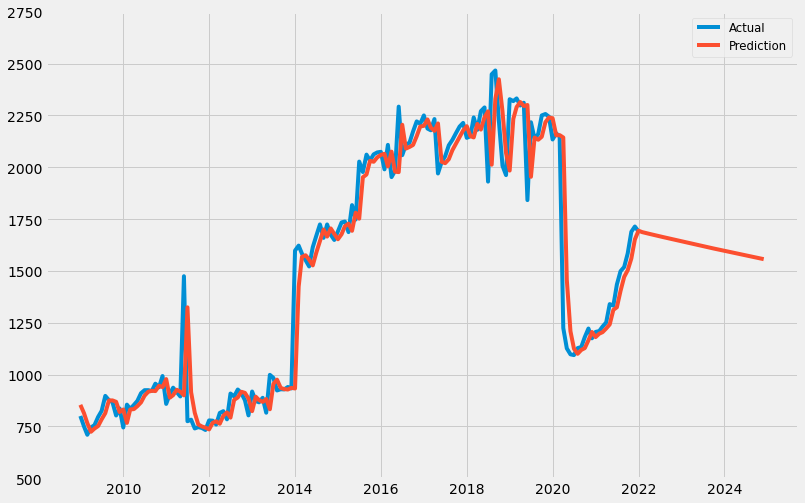

In [34]:
plt.figure(figsize=(12,8))
plt.plot(DAFM_Act, label="Actual")
plt.plot(DAFM_pred_act_df, label = "Prediction")
plt.legend(loc='best',fontsize='small')
plt.show()

### Linear Regression

In [35]:
temp_df = DAFM_nor.copy()
temp_df.reset_index(inplace =True)
temp_df

,date,price
0,2008-01-01,0.197472
1,2008-02-01,0.242857
2,2008-03-01,0.216929
3,2008-04-01,0.171456
4,2008-05-01,0.171888
...,...,...
164,2021-09-01,0.460496
165,2021-10-01,0.497753
166,2021-11-01,0.557326
167,2021-12-01,0.571687


In [36]:
temp_df['time'] = temp_df['date'].apply(lambda x: x.value)
mask = np.random.rand(len(temp_df)) < 0.7
train = temp_df[mask]
test = temp_df[~mask]
train, test

(          date     price                 time
 1   2008-02-01  0.242857  1201824000000000000
 2   2008-03-01  0.216929  1204329600000000000
 3   2008-04-01  0.171456  1207008000000000000
 4   2008-05-01  0.171888  1209600000000000000
 6   2008-07-01  0.185976  1214870400000000000
 ..         ...       ...                  ...
 163 2021-08-01  0.448992  1627776000000000000
 164 2021-09-01  0.460496  1630454400000000000
 166 2021-11-01  0.557326  1635724800000000000
 167 2021-12-01  0.571687  1638316800000000000
 168 2022-01-01  0.558152  1640995200000000000
 
 [123 rows x 3 columns],
           date     price                 time
 0   2008-01-01  0.197472  1199145600000000000
 5   2008-06-01  0.219161  1212278400000000000
 10  2008-11-01  0.090990  1225497600000000000
 12  2009-01-01  0.051558  1230768000000000000
 16  2009-05-01  0.026369  1241136000000000000
 17  2009-06-01  0.048945  1243814400000000000
 19  2009-08-01  0.106665  1249084800000000000
 28  2010-05-01  0.093036  127267

In [37]:
X_train = train.time
X_train = X_train.values.reshape((-1,1))
y_train = train['price'].values
X_train[:10], y_train[:10]

(array([[1201824000000000000],
        [1204329600000000000],
        [1207008000000000000],
        [1209600000000000000],
        [1214870400000000000],
        [1217548800000000000],
        [1220227200000000000],
        [1222819200000000000],
        [1228089600000000000],
        [1233446400000000000]], dtype=int64),
 array([0.24285722, 0.21692868, 0.17145645, 0.17188839, 0.18597631,
        0.16862635, 0.16342984, 0.14988236, 0.07422014, 0.02281081]))

In [38]:
X_test = test.time
X_test = X_test.values.reshape((-1,1))
y_test = test['price'].values
X_test[:10], y_test[:10]

(array([[1199145600000000000],
        [1212278400000000000],
        [1225497600000000000],
        [1230768000000000000],
        [1241136000000000000],
        [1243814400000000000],
        [1249084800000000000],
        [1272672000000000000],
        [1288569600000000000],
        [1312156800000000000]], dtype=int64),
 array([0.19747176, 0.21916076, 0.09098988, 0.05155798, 0.02636868,
        0.04894539, 0.10666495, 0.09303623, 0.13029786, 0.04139637]))

In [39]:
X = np.concatenate((X_train, X_test), axis = 0)
y = np.concatenate((y_train, y_test), axis = 0)

In [40]:
DAFM_nor_linreg = LinearRegression().fit(X_train, y_train)

In [41]:
print('linear model coeff or slope (w): {}'.format(DAFM_nor_linreg.coef_))
print('linear model intercept (b): {:.3f}'.format(DAFM_nor_linreg.intercept_))
print('R-squared score (training): {:.3f}'.format(DAFM_nor_linreg.score(X_train, y_train)))
print('R-squared score (test): {:.3f}'.format(DAFM_nor_linreg.score(X_test, y_test)))

linear model coeff or slope (w): [1.68699702e-18]
linear model intercept (b): -1.985
R-squared score (training): 0.462
R-squared score (test): 0.396


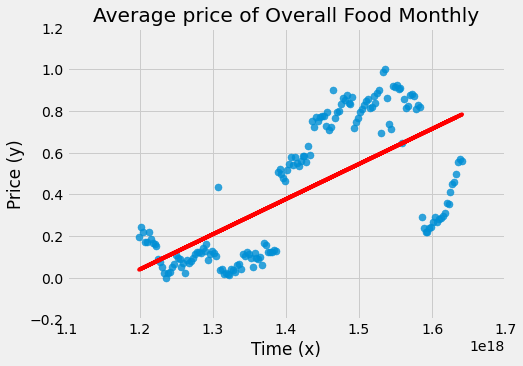

In [42]:
plt.figure(figsize=(7,5))
plt.scatter(X, y, marker= 'o', s=50, alpha=0.8)
plt.plot(X, DAFM_nor_linreg.coef_ * X + DAFM_nor_linreg.intercept_, 'r-')
plt.title('Average price of Overall Food Monthly')
plt.xlabel('Time (x)')
plt.ylabel('Price (y)')
plt.show()

In [43]:
DAFM_linear_predict = pd.DataFrame(pd.date_range(start=pred_st_date,end=pred_end_date, freq='MS').to_pydatetime().tolist(), columns=['date'])
DAFM_linear_predict['time'] = DAFM_linear_predict['date'].apply(lambda x: x.value)
DAFM_linear_predict

,date,time
0,2009-01-01,1230768000000000000
1,2009-02-01,1233446400000000000
2,2009-03-01,1235865600000000000
3,2009-04-01,1238544000000000000
4,2009-05-01,1241136000000000000
...,...,...
188,2024-09-01,1725148800000000000
189,2024-10-01,1727740800000000000
190,2024-11-01,1730419200000000000
191,2024-12-01,1733011200000000000


In [44]:
time_predict = np.array(DAFM_linear_predict['time']).reshape((-1, 1))
DAFM_linear_predict['price'] = DAFM_nor_linreg.predict(time_predict)
DAFM_linear_predict

,date,time,price
0,2009-01-01,1230768000000000000,0.091640
1,2009-02-01,1233446400000000000,0.096158
2,2009-03-01,1235865600000000000,0.100239
3,2009-04-01,1238544000000000000,0.104758
4,2009-05-01,1241136000000000000,0.109130
...,...,...,...
188,2024-09-01,1725148800000000000,0.925658
189,2024-10-01,1727740800000000000,0.930031
190,2024-11-01,1730419200000000000,0.934550
191,2024-12-01,1733011200000000000,0.938922


In [45]:
DAFM_linear_normalized_predict = DAFM_linear_predict.copy()
DAFM_linear_normalized_predict = DAFM_linear_normalized_predict[['date', 'price']]
DAFM_linear_normalized_predict.set_index('date', inplace=True)
DAFM_linear_normalized_predict

,price
date,
2009-01-01,0.091640
2009-02-01,0.096158
2009-03-01,0.100239
2009-04-01,0.104758
2009-05-01,0.109130
...,...
2024-09-01,0.925658
2024-10-01,0.930031
2024-11-01,0.934550


##### Unnormalized the data

In [46]:
DAFM_pred_act_linear = scaler.inverse_transform(DAFM_linear_normalized_predict)
DAFM_pred_act_linear_df = pd.DataFrame(DAFM_pred_act_linear)
DAFM_pred_act_linear_df['date'] = DAFM_linear_predict['date']
DAFM_pred_act_linear_df.columns = ['Predicted Price (KG)', 'date']
DAFM_pred_act_linear_df.set_index('date', inplace=True)
DAFM_pred_act_linear_df

,Predicted Price (KG)
date,
2009-01-01,870.945836
2009-02-01,878.883535
2009-03-01,886.053071
2009-04-01,893.990770
2009-05-01,901.672415
...,...
2024-09-01,2336.091558
2024-10-01,2343.773203
2024-11-01,2351.710903
